In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path
import shutil, re
p = Path("/content/drive/MyDrive/AASIST_Project/finetune_aasist.py")
bak = Path(str(p) + ".before_run.bak")
if not bak.exists():
    shutil.copy2(p, bak)          # keep the first backup only
s = p.read_text()

# 1. natural-timing CallHome audio (no-op if already _mix)
s = s.replace('call*_opponent.wav', 'call*_mix.wav')

# 2. EER helper works with a float OR a tuple from compute_eer
if "_e = compute_eer(" in s:
    print("EER patch already applied")
else:
    old = 'res["EER_" + name] = 100 * compute_eer(val_labs, 1.0 - p_spoof(model, dev, ys))\n'
    new = ('_e = compute_eer(val_labs, 1.0 - p_spoof(model, dev, ys))\n'
           '        res["EER_" + name] = 100 * (_e[0] if isinstance(_e, tuple) else _e)\n')
    assert old in s, "EER line not found"
    s = s.replace(old, new)

# 3. optional --freeze-bn
if "--freeze-bn" in s:
    print("freeze-bn argument already present")
else:
    old = '    ap.add_argument("--skip-baseline", action="store_true")'
    assert old in s
    s = s.replace(old, old + '\n    ap.add_argument("--freeze-bn", action="store_true")')

if "args.freeze_bn" in s:
    print("freeze-bn loop already present")
else:
    old = '        model.train()\n        t0, losses = time.time(), []'
    new = ('        model.train()\n        if args.freeze_bn:\n            for m in model.modules():\n'
           '                if isinstance(m, torch.nn.modules.batchnorm._BatchNorm):\n                    m.eval()\n'
           '        t0, losses = time.time(), []')
    assert old in s
    s = s.replace(old, new)

p.write_text(s); print("patched")

EER patch already applied
freeze-bn argument already present
freeze-bn loop already present
patched


In [5]:
!python -u /content/drive/MyDrive/AASIST_Project/finetune_aasist.py \
  --la-root "/content/drive/MyDrive/AASIST_Project/colab_subset" \
  --protocol "/content/drive/MyDrive/AASIST_Project/colab_subset/subset_protocol.txt" \
  --callhome-dir "/content/drive/MyDrive/AASIST_Project/callhome_out" \
  --init "/content/drive/MyDrive/AASIST_Project/aasist/models/weights/AASIST.pth" \
  --out "/content/drive/MyDrive/AASIST_Project/runA" \
  --epochs 3 --steps-per-epoch 150 --batch-size 16 --val-per-class 100 --device cuda

LA clips with labels: 400   train: 360 (bonafide 182, spoof 178)
validation: 40 clips from 10% hold-out of LA_T_ (no dev clips found; same speakers, so optimistic)
CallHome: 5 calls -> 3 for training, 2 held out
epoch 0 (pretrained) [10s]  EER_asis=0.0  EER_no_pauses=10.1  EER_pad_edges=5.1  EER_phone8k=0.0  EER_gain-12dB=5.1  callhome_FA%=18.1  callhome_mean_p=0.227  select=0.131
  step 1/450  loss 1.0747  (5s)
  step 25/450  loss 2.5706  (49s)
  step 50/450  loss 2.2436  (86s)
  step 75/450  loss 1.5968  (118s)
  step 100/450  loss 1.7986  (148s)
  step 125/450  loss 1.6597  (176s)
  step 150/450  loss 1.4451  (205s)
epoch 1  loss 1.8857  EER_asis=0.0  EER_no_pauses=5.1  EER_pad_edges=0.0  EER_phone8k=0.0  EER_gain-12dB=0.0  callhome_FA%=24.1  callhome_mean_p=0.246  select=0.131
  -> new best.pth
  step 175/450  loss 1.0908  (29s)
  step 200/450  loss 1.2275  (58s)
  step 225/450  loss 1.3703  (88s)
  step 250/450  loss 1.0783  (116s)
  step 275/450  loss 1.0320  (144s)
  step 300/45

In [6]:
!python -u /content/drive/MyDrive/AASIST_Project/finetune_aasist.py \
  --la-root "/content/drive/MyDrive/AASIST_Project/colab_subset" \
  --protocol "/content/drive/MyDrive/AASIST_Project/colab_subset/subset_protocol.txt" \
  --callhome-dir "/content/drive/MyDrive/AASIST_Project/callhome_out" \
  --init "/content/drive/MyDrive/AASIST_Project/aasist/models/weights/AASIST.pth" \
  --out "/content/drive/MyDrive/AASIST_Project/runB" \
  --epochs 3 --steps-per-epoch 150 --batch-size 16 --val-per-class 100 --lr 1e-5 --freeze-bn --device cuda

LA clips with labels: 400   train: 360 (bonafide 182, spoof 178)
validation: 40 clips from 10% hold-out of LA_T_ (no dev clips found; same speakers, so optimistic)
CallHome: 5 calls -> 3 for training, 2 held out
epoch 0 (pretrained) [6s]  EER_asis=0.0  EER_no_pauses=10.1  EER_pad_edges=5.1  EER_phone8k=0.0  EER_gain-12dB=5.1  callhome_FA%=18.1  callhome_mean_p=0.227  select=0.131
  step 1/450  loss 0.7620  (3s)
  step 25/450  loss 0.9774  (26s)
  step 50/450  loss 0.9057  (52s)
  step 75/450  loss 0.8131  (79s)
  step 100/450  loss 0.7695  (105s)
  step 125/450  loss 0.5540  (130s)
  step 150/450  loss 0.6243  (156s)
epoch 1  loss 0.7740  EER_asis=0.0  EER_no_pauses=2.3  EER_pad_edges=5.1  EER_phone8k=0.0  EER_gain-12dB=10.1  callhome_FA%=7.8  callhome_mean_p=0.144  select=0.074
  -> new best.pth
  step 175/450  loss 0.6431  (26s)
  step 200/450  loss 0.5222  (53s)
  step 225/450  loss 0.6107  (78s)
  step 250/450  loss 0.6244  (104s)
  step 275/450  loss 0.5556  (131s)
  step 300/450 

In [7]:
import pandas as pd
cols = ["epoch","train_loss","EER_asis","EER_no_pauses","EER_pad_edges","EER_phone8k","EER_gain-12dB","callhome_FA%","callhome_mean_p","select"]
for r in ("runA", "runB"):
    print(r); display(pd.read_csv(f"/content/drive/MyDrive/AASIST_Project/{r}/metrics.csv")[cols].round(3))

runA


,epoch,train_loss,EER_asis,EER_no_pauses,EER_pad_edges,EER_phone8k,EER_gain-12dB,callhome_FA%,callhome_mean_p,select
0,0,NaN,0.0,10.101,5.051,0.0,5.051,18.103,0.227,0.131
1,1,1.886,0.0,5.051,0.000,0.0,0.000,24.138,0.246,0.131
2,2,1.123,0.0,7.323,5.051,0.0,7.323,13.793,0.164,0.108
3,3,0.854,0.0,5.051,5.051,0.0,2.778,7.759,0.088,0.065


runB


,epoch,train_loss,EER_asis,EER_no_pauses,EER_pad_edges,EER_phone8k,EER_gain-12dB,callhome_FA%,callhome_mean_p,select
0,0,NaN,0.0,10.101,5.051,0.0,5.051,18.103,0.227,0.131
1,1,0.774,0.0,2.273,5.051,0.0,10.101,7.759,0.144,0.074
2,2,0.571,0.0,2.273,5.051,0.0,10.101,6.034,0.111,0.065
3,3,0.456,0.0,2.273,5.051,0.0,10.101,6.034,0.106,0.065


In [8]:
import os
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import sys

PROJECT = "/content/drive/MyDrive/AASIST_Project"
sys.path.insert(0, PROJECT)

import aasist_io
from finetune_aasist import p_spoof, SR, N

# Let's target the exact paths for call004 and call005
call_paths = [
    os.path.join(PROJECT, "callhome_out/call004_mix.wav"),
    os.path.join(PROJECT, "callhome_out/call005_mix.wav")
]

# Ensure files exist
for path in call_paths:
    print(f"File {os.path.basename(path)} exists:", os.path.exists(path))


File call004_mix.wav exists: True
File call005_mix.wav exists: True


In [9]:
def evaluate_specific_calls(model_dir, model_name, device="cuda"):
    # Use the correct load function from aasist_io
    checkpoint_path = os.path.join(PROJECT, model_dir, model_name)
    if not os.path.exists(checkpoint_path):
        print(f"Checkpoint missing: {checkpoint_path}")
        return

    model, device = aasist_io.load(checkpoint=checkpoint_path, device=device, train=False)
    model.eval()

    print(f"\n====== {model_dir}/{model_name} ======")

    hop_s = 2.0
    max_s = 120.0

    for path in call_paths:
        if not os.path.exists(path):
            continue
        name = os.path.basename(path)
        x, _ = sf.read(path, frames=int(max_s * SR), dtype="float32", always_2d=True)
        x = x.mean(axis=1)

        # Cut 4s sliding windows
        windows = [x[s:s + N] for s in range(0, max(1, len(x) - N + 1), int(hop_s * SR))]

        # Get probabilities of being spoof (1.0 = spoof, 0.0 = bonafide)
        probs = p_spoof(model, device, windows)

        fa_rate = 100 * np.mean(probs > 0.5)
        mean_p = np.mean(probs)

        print(f"{name:20} | Segments: {len(probs):3d} | Mean Spoof Prob: {mean_p:.3f} | FA Rate (>0.5): {fa_rate:.1f}%")

# Evaluate both runA and runB best weights
evaluate_specific_calls("runA", "best.pth")
evaluate_specific_calls("runB", "best.pth")


====== runA/best.pth ======
call004_mix.wav      | Segments:  58 | Mean Spoof Prob: 0.043 | FA Rate (>0.5): 1.7%
call005_mix.wav      | Segments:  58 | Mean Spoof Prob: 0.132 | FA Rate (>0.5): 13.8%

====== runB/best.pth ======
call004_mix.wav      | Segments:  58 | Mean Spoof Prob: 0.074 | FA Rate (>0.5): 1.7%
call005_mix.wav      | Segments:  58 | Mean Spoof Prob: 0.149 | FA Rate (>0.5): 10.3%


In [10]:
opponent_paths = [
    os.path.join(PROJECT, "callhome_out/call004_opponent.wav"),
    os.path.join(PROJECT, "callhome_out/call005_opponent.wav")
]

def evaluate_opponent_calls(model_dir, model_name, device="cuda"):
    checkpoint_path = os.path.join(PROJECT, model_dir, model_name)
    if not os.path.exists(checkpoint_path):
        print(f"Checkpoint missing: {checkpoint_path}")
        return

    model, device = aasist_io.load(checkpoint=checkpoint_path, device=device, train=False)
    model.eval()

    print(f"\n====== {model_dir}/{model_name} (Opponent Files) ======")

    hop_s = 2.0
    max_s = 120.0

    for path in opponent_paths:
        if not os.path.exists(path):
            print(f"File missing: {os.path.basename(path)}")
            continue
        name = os.path.basename(path)
        x, _ = sf.read(path, frames=int(max_s * SR), dtype="float32", always_2d=True)
        x = x.mean(axis=1)

        windows = [x[s:s + N] for s in range(0, max(1, len(x) - N + 1), int(hop_s * SR))]
        probs = p_spoof(model, device, windows)

        fa_rate = 100 * np.mean(probs > 0.5)
        mean_p = np.mean(probs)

        print(f"{name:25} | Segments: {len(probs):3d} | Mean Spoof Prob: {mean_p:.3f} | FA Rate (>0.5): {fa_rate:.1f}%")

evaluate_opponent_calls("runA", "best.pth")
evaluate_opponent_calls("runB", "best.pth")


====== runA/best.pth (Opponent Files) ======
call004_opponent.wav      | Segments:  45 | Mean Spoof Prob: 0.071 | FA Rate (>0.5): 6.7%
call005_opponent.wav      | Segments:  58 | Mean Spoof Prob: 0.028 | FA Rate (>0.5): 1.7%

====== runB/best.pth (Opponent Files) ======
call004_opponent.wav      | Segments:  45 | Mean Spoof Prob: 0.075 | FA Rate (>0.5): 0.0%
call005_opponent.wav      | Segments:  58 | Mean Spoof Prob: 0.144 | FA Rate (>0.5): 5.2%


In [11]:
import os
import numpy as np
import soundfile as sf
import torch
import sys

PROJECT = "/content/drive/MyDrive/AASIST_Project"
sys.path.insert(0, PROJECT)

import aasist_io
import augment
from finetune_aasist import p_spoof, SR, N

# Define the five conditions based on augment.py functions
# Note: rng with seed=0 ensures deterministic evaluation
rng = np.random.default_rng(0)

CONDITIONS = {
    "Original": lambda x: x,
    "Trim Edges": lambda x: augment.trim_edges(x),
    "Pause Removal": lambda x: augment.no_pauses(x),
    "Noise Padding": lambda x: augment.pad_random(x, rng),
    "Phone 8kHz": lambda x: augment.phone_channel(x, rng)
}

# Prepare opponent audio files
opp_paths = [
    os.path.join(PROJECT, "callhome_out/call004_opponent.wav"),
    os.path.join(PROJECT, "callhome_out/call005_opponent.wav")
]

# Checkpoints to test
checkpoints = {
    "Pretrained Baseline": None,
    "RunA (best.pth)": os.path.join(PROJECT, "runA/best.pth"),
    "RunB (best.pth)": os.path.join(PROJECT, "runB/best.pth")
}

hop_s = 2.0
max_s = 120.0

for cp_name, cp_path in checkpoints.items():
    print(f"\nEvaluating: {cp_name}")
    # Load model using the verified aasist_io interface
    model, device = aasist_io.load(checkpoint=cp_path, device="cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    for path in opp_paths:
        if not os.path.exists(path):
            continue
        wav_name = os.path.basename(path)

        # Read audio
        orig_x, _ = sf.read(path, frames=int(max_s * SR), dtype="float32", always_2d=True)
        orig_x = orig_x.mean(axis=1)

        print(f"  File: {wav_name}")
        for cond_name, cond_fn in CONDITIONS.items():
            # Apply transformation
            try:
                x = cond_fn(orig_x.copy())
                # Ensure length is long enough for model input, tile if too short
                x = augment.crop_or_tile(x, rng, N)
            except Exception as e:
                print(f"    Error transforming {cond_name}: {e}")
                continue

            # Create sliding windows of size N (4 seconds)
            windows = [x[s:s + N] for s in range(0, max(1, len(x) - N + 1), int(hop_s * SR))]
            probs = p_spoof(model, device, windows)

            mean_p = np.mean(probs)
            fa_rate = 100 * np.mean(probs > 0.5)
            print(f"    - {cond_name:15} | Mean Spoof Prob: {mean_p:.3f} | FA Rate (>0.5): {fa_rate:.1f}%")



Evaluating: Pretrained Baseline
  File: call004_opponent.wav
    - Original        | Mean Spoof Prob: 0.012 | FA Rate (>0.5): 0.0%
    - Trim Edges      | Mean Spoof Prob: 0.002 | FA Rate (>0.5): 0.0%
    - Pause Removal   | Mean Spoof Prob: 0.062 | FA Rate (>0.5): 0.0%
    - Noise Padding   | Mean Spoof Prob: 0.020 | FA Rate (>0.5): 0.0%
    - Phone 8kHz      | Mean Spoof Prob: 0.033 | FA Rate (>0.5): 0.0%
  File: call005_opponent.wav
    - Original        | Mean Spoof Prob: 0.450 | FA Rate (>0.5): 0.0%
    - Trim Edges      | Mean Spoof Prob: 0.952 | FA Rate (>0.5): 100.0%
    - Pause Removal   | Mean Spoof Prob: 0.262 | FA Rate (>0.5): 0.0%
    - Noise Padding   | Mean Spoof Prob: 0.343 | FA Rate (>0.5): 0.0%
    - Phone 8kHz      | Mean Spoof Prob: 0.066 | FA Rate (>0.5): 0.0%

Evaluating: RunA (best.pth)
  File: call004_opponent.wav
    - Original        | Mean Spoof Prob: 0.442 | FA Rate (>0.5): 0.0%
    - Trim Edges      | Mean Spoof Prob: 0.003 | FA Rate (>0.5): 0.0%
    - Pau

In [12]:
import os
import numpy as np
import soundfile as sf
import torch
import sys

PROJECT = "/content/drive/MyDrive/AASIST_Project"
sys.path.insert(0, PROJECT)

import aasist_io
import augment
from finetune_aasist import p_spoof, SR, N

rng = np.random.default_rng(0)

CONDITIONS = {
    "Original": lambda x: x,
    "Trim Edges": lambda x: augment.trim_edges(x),
    "Pause Removal": lambda x: augment.no_pauses(x),
    "Noise Padding": lambda x: augment.pad_random(x, rng),
    "Phone 8kHz": lambda x: augment.phone_channel(x, rng)
}

# Include call001, call002, call003, call004, and call005
opp_paths = [
    os.path.join(PROJECT, f"callhome_out/call00{i}_opponent.wav") for i in range(1, 6)
]

checkpoints = {
    "Pretrained Baseline": None,
    "RunA (best.pth)": os.path.join(PROJECT, "runA/best.pth"),
    "RunB (best.pth)": os.path.join(PROJECT, "runB/best.pth")
}

hop_s = 2.0
max_s = 120.0

for cp_name, cp_path in checkpoints.items():
    print(f"\n==================== Evaluating: {cp_name} ====================")
    model, device = aasist_io.load(checkpoint=cp_path, device="cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    for path in opp_paths:
        if not os.path.exists(path):
            print(f"  File missing: {os.path.basename(path)}")
            continue
        wav_name = os.path.basename(path)
        print(f"\n  File: {wav_name}")

        # Read audio
        orig_x, _ = sf.read(path, frames=int(max_s * SR), dtype="float32", always_2d=True)
        orig_x = orig_x.mean(axis=1)

        for cond_name, cond_fn in CONDITIONS.items():
            try:
                x = cond_fn(orig_x.copy())
                x = augment.crop_or_tile(x, rng, N)
            except Exception as e:
                print(f"    Error transforming {cond_name}: {e}")
                continue

            # Create sliding windows of size N (4 seconds)
            windows = [x[s:s + N] for s in range(0, max(1, len(x) - N + 1), int(hop_s * SR))]
            probs = p_spoof(model, device, windows)

            mean_p = np.mean(probs)
            fa_rate = 100 * np.mean(probs > 0.5)
            print(f"    - {cond_name:15} | Segments: {len(probs):3d} | Mean Spoof Prob: {mean_p:.3f} | FA Rate (>0.5): {fa_rate:.1f}%")



==================== Evaluating: Pretrained Baseline ====================

  File: call001_opponent.wav
    - Original        | Segments:   1 | Mean Spoof Prob: 0.982 | FA Rate (>0.5): 100.0%
    - Trim Edges      | Segments:   1 | Mean Spoof Prob: 0.954 | FA Rate (>0.5): 100.0%
    - Pause Removal   | Segments:   1 | Mean Spoof Prob: 1.000 | FA Rate (>0.5): 100.0%
    - Noise Padding   | Segments:   1 | Mean Spoof Prob: 0.999 | FA Rate (>0.5): 100.0%
    - Phone 8kHz      | Segments:   1 | Mean Spoof Prob: 0.999 | FA Rate (>0.5): 100.0%

  File: call002_opponent.wav
    - Original        | Segments:   1 | Mean Spoof Prob: 0.018 | FA Rate (>0.5): 0.0%
    - Trim Edges      | Segments:   1 | Mean Spoof Prob: 0.033 | FA Rate (>0.5): 0.0%
    - Pause Removal   | Segments:   1 | Mean Spoof Prob: 0.047 | FA Rate (>0.5): 0.0%
    - Noise Padding   | Segments:   1 | Mean Spoof Prob: 0.003 | FA Rate (>0.5): 0.0%
    - Phone 8kHz      | Segments:   1 | Mean Spoof Prob: 0.614 | FA Rate (>0.5): 

In [13]:
import os
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import sys

PROJECT = "/content/drive/MyDrive/AASIST_Project"
sys.path.insert(0, PROJECT)

import aasist_io
import augment
from finetune_aasist import p_spoof, SR, N

# Configure paths
opp_paths = [os.path.join(PROJECT, f"callhome_out/call00{i}_opponent.wav") for i in range(1, 6)]
checkpoints = {
    "Baseline": None,
    "RunA": os.path.join(PROJECT, "runA/best.pth"),
    "RunB": os.path.join(PROJECT, "runB/best.pth")
}

hop_s = 2.0
max_s = 120.0
hop_samples = int(hop_s * SR)

results_list = []

for cp_name, cp_path in checkpoints.items():
    print(f"Evaluating {cp_name}...")
    model, device = aasist_io.load(checkpoint=cp_path, device="cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    for path in opp_paths:
        if not os.path.exists(path):
            continue
        wav_name = os.path.basename(path)
        call_id = wav_name.split("_")[0]

        # Load full audio (up to max_s seconds)
        orig_x, _ = sf.read(path, frames=int(max_s * SR), dtype="float32", always_2d=True)
        orig_x = orig_x.mean(axis=1)

        # Reset RNG seed for deterministic condition transformation
        rng = np.random.default_rng(0)

        CONDITIONS = {
            "Original": lambda x: x,
            "Trim Edges": lambda x: augment.trim_edges(x),
            "Pause Removal": lambda x: augment.no_pauses(x),
            "Noise Padding": lambda x: augment.pad_random(x, rng),
            "Phone 8kHz": lambda x: augment.phone_channel(x, rng)
        }

        for cond_name, cond_fn in CONDITIONS.items():
            try:
                # Reset the RNG seed so each model evaluates the exact same random transformations
                rng = np.random.default_rng(0)
                transformed_x = cond_fn(orig_x.copy())
            except Exception as e:
                print(f"    Error transforming {cond_name} for {call_id}: {e}")
                continue

            # Slide across the full length of the transformed audio
            windows = []
            for start in range(0, len(transformed_x), hop_samples):
                end = start + N
                window = transformed_x[start:end]
                if len(window) < N:
                    # Tile if the window is shorter than 4 seconds
                    window = np.tile(window, int(np.ceil(N / len(window))))[:N]
                windows.append(window)

            probs = np.array(p_spoof(model, device, windows))

            results_list.append({
                "Model": cp_name,
                "Call": call_id,
                "Condition": cond_name,
                "Windows": len(probs),
                "Mean Spoof": np.mean(probs),
                "Median Spoof": np.median(probs),
                "95th% Spoof": np.percentile(probs, 95),
                "FA Rate": 100 * np.mean(probs > 0.5)
            })

# Create and display structured dataframe
df_results = pd.DataFrame(results_list)
pd.set_option('display.max_rows', 100)
display(df_results)

Evaluating Baseline...
Evaluating RunA...
Evaluating RunB...


,Model,Call,Condition,Windows,Mean Spoof,Median Spoof,95th% Spoof,FA Rate
0,Baseline,call001,Original,30,0.731723,0.941737,0.999345,73.333333
1,Baseline,call001,Trim Edges,29,0.754129,0.946176,0.999372,75.862069
2,Baseline,call001,Pause Removal,27,0.760469,0.966100,0.999725,77.777778
3,Baseline,call001,Noise Padding,30,0.677922,0.922470,0.998924,73.333333
4,Baseline,call001,Phone 8kHz,30,0.850156,0.989275,0.999829,86.666667
5,Baseline,call002,Original,60,0.162053,0.053861,0.637099,11.666667
6,Baseline,call002,Trim Edges,60,0.162053,0.053861,0.637099,11.666667
7,Baseline,call002,Pause Removal,55,0.259246,0.101948,0.840244,20.000000
8,Baseline,call002,Noise Padding,61,0.162809,0.039792,0.791627,11.475410
9,Baseline,call002,Phone 8kHz,60,0.321042,0.153196,0.934990,33.333333


In [14]:
import os
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import sys

PROJECT = "/content/drive/MyDrive/AASIST_Project"
sys.path.insert(0, PROJECT)

import aasist_io
from finetune_aasist import p_spoof, SR, N

# Configure Target Files
call_ids = ["call001", "call002", "call003", "call004", "call005"]
checkpoints = {
    "RunA": os.path.join(PROJECT, "runA/best.pth"),
    "RunB": os.path.join(PROJECT, "runB/best.pth")
}

hop_s = 2.0
max_s = 120.0
hop_samples = int(hop_s * SR)

comparison_results = []

for cp_name, cp_path in checkpoints.items():
    model, device = aasist_io.load(checkpoint=cp_path, device="cuda" if torch.cuda.is_available() else "cpu")
    model.eval()

    for cid in call_ids:
        for mode in ["mix", "opponent"]:
            filename = f"{cid}_{mode}.wav"
            path = os.path.join(PROJECT, "callhome_out", filename)
            if not os.path.exists(path):
                continue

            # Load and mix down mono
            x, _ = sf.read(path, frames=int(max_s * SR), dtype="float32", always_2d=True)
            x = x.mean(axis=1)

            # Create 4s sliding windows with 2s hop
            windows = []
            for start in range(0, len(x), hop_samples):
                end = start + N
                window = x[start:end]
                if len(window) < N:
                    window = np.tile(window, int(np.ceil(N / len(window))))[:N]
                windows.append(window)

            # Predict spoof probabilities
            probs = np.array(p_spoof(model, device, windows))

            comparison_results.append({
                "Model": cp_name,
                "Call": cid,
                "Mode": mode,
                "Windows": len(probs),
                "Mean Spoof": np.mean(probs),
                "Median Spoof": np.median(probs),
                "FA Rate (%)": 100 * np.mean(probs > 0.5)
            })

# Construct and display DataFrame comparison table
df_comp = pd.DataFrame(comparison_results)
display(df_comp)

,Model,Call,Mode,Windows,Mean Spoof,Median Spoof,FA Rate (%)
0,RunA,call001,mix,60,0.234288,0.015856,23.333333
1,RunA,call001,opponent,30,0.239572,0.015298,26.666667
2,RunA,call002,mix,60,0.268642,0.117572,20.000000
3,RunA,call002,opponent,60,0.131039,0.040296,6.666667
4,RunA,call003,mix,60,0.086923,0.030031,5.000000
5,RunA,call003,opponent,60,0.084042,0.039048,3.333333
6,RunA,call004,mix,60,0.043914,0.002582,1.666667
7,RunA,call004,opponent,47,0.068299,0.004269,6.382979
8,RunA,call005,mix,60,0.127729,0.000929,13.333333
9,RunA,call005,opponent,60,0.027734,0.001016,1.666667


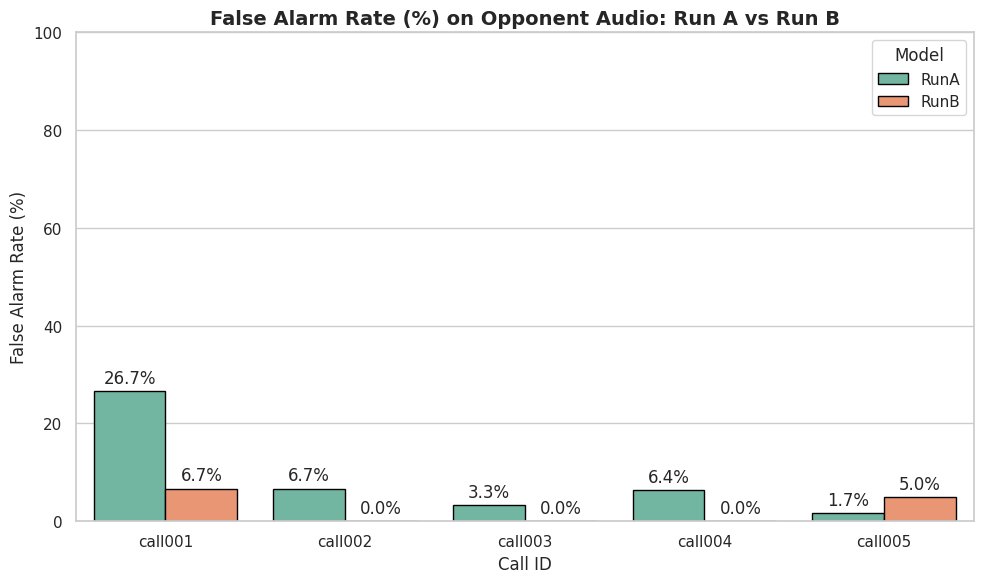

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure we have our comparison dataframe ready
df_filtered = df_comp[df_comp["Mode"] == "opponent"].copy()

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=df_filtered,
    x="Call",
    y="FA Rate (%)",
    hue="Model",
    palette="Set2",
    edgecolor="black"
)

plt.title("False Alarm Rate (%) on Opponent Audio: Run A vs Run B", fontsize=14, fontweight="bold")
plt.xlabel("Call ID", fontsize=12)
plt.ylabel("False Alarm Rate (%)", fontsize=12)
plt.ylim(0, 100)

# Annotate the bars with their heights
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()